## Model 4: Memory Consolidation

Repeated reinforcement may do more than temporarily increase memory strength. It may also make the memory more resistant to future decay.

To model this, we allow the decay rate ƛ to decrease after each successful review:

ƛ_new = ƛ * c

where c is a consolidation factor between 0 and 1.

We predict that repeated reviews will produce increasingly stable memories, allowing review intervals to become longer over time.

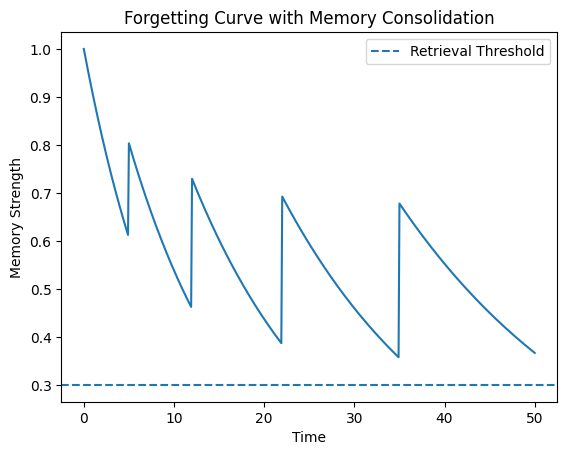

In [1]:
import numpy as np
import matplotlib.pyplot as plt

retrieval_threshold = 0.3

learning_rate = 0.5
initial_decay_rate = 0.1
decay_rate = initial_decay_rate
consolidation_factor = 0.8

review_times = [5, 12, 22, 35]
next_review_index = 0

time = np.linspace(0, 50, 501)
dt = time[1] - time[0]

memory_strength = np.zeros(len(time))
memory_strength[0] = 1.0

for i in range(1, len(time)):
    memory_strength[i] = memory_strength[i - 1] * np.exp(-decay_rate * dt)

    if next_review_index < len(review_times):
        review_time = review_times[next_review_index]

        if time[i - 1] < review_time <= time[i]:
            memory_strength[i] = memory_strength[i] + learning_rate * (1 - memory_strength[i])
            decay_rate *= consolidation_factor
            next_review_index += 1

        
plt.plot(time, memory_strength)
plt.axhline(y=retrieval_threshold, linestyle='--', label='Retrieval Threshold')

plt.xlabel('Time')
plt.ylabel('Memory Strength')
plt.title('Forgetting Curve with Memory Consolidation')
plt.legend()

plt.show()


### Interpretation of Model 4

Model 4 demonstrates that reducing the decay rate after successful reinforcement allows increasingly spaced reviews to maintain the memory above the retrieval threshold.

Note: this behavior follows assumption built into the model and should not be interpreted as evidence that biological memory follows these exact equations.